# AA 279B HW 4

## Imports

In [29]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## MATLAB

In [30]:
import matlab.engine
from matlab.engine import MatlabEngine

In [31]:
# 1. Start the MATLAB process in the background
print("Starting MATLAB engine...")
eng: MatlabEngine = matlab.engine.start_matlab()

Starting MATLAB engine...


In [32]:
stop = False
if stop:
    eng.quit()

## Setup

In [33]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [34]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from tqdm import tqdm

from constants import DEG_TO_RAD, AU_TO_KM, MU_SUN, DAY_TO_SEC, R_SUN, HOUR_TO_SEC
from orbital import rv_from_coe
from plotting import plot_3d
from spacetime import greg_to_jd

## Problem 1

### Part a

In [35]:
def hci_rv(planet_num: int, jd: float):
    """Heliocentric position and velocity using https://ssd.jpl.nasa.gov/planets/approx_pos.html

    From `AA279j2000_planetary_elements` matlab:
    elements:  row vector of J2000 orbital elements for "planet_id"
    - a             semimajor axis [AU]
    - e             eccentricity
    - i             inclination [deg]
    - OMEGA         longitude of the ascending node [deg]
    - omega_bar     longitude of perihelion [deg]
    - L             mean longitude [deg]      

    Parameters
    ----------
    planet_num : int
        1 (Mercury) to 9 (Pluto) BUT further ones beyond Mars technically require more coefficients
    jd : float
        Julian Date
        
    Returns
    ----------
    r_hci : np.ndarray (3,)
        Heliocentric position
    v_hci : np.ndarray (3,)
        Heliocentric velocity
    """
    
    assert planet_num >= 1
    assert planet_num <= 9

    tt_jd = (jd - 2451545.0) / 36525.0
    
    elements, rates = eng.AA279j2000_planetary_elements(planet_num, nargout=2)
    
    
    #  1. Value of six elements (angles in degrees)
    a_au, e, i_deg, raan_deg, w_bar_deg, L_deg = [
        x + dx*tt_jd for x,dx in zip(elements[0], rates[0])
    ]
    
    #  2. aop and M
    aop = (w_bar_deg - raan_deg) * DEG_TO_RAD
    M = (L_deg - w_bar_deg) * DEG_TO_RAD
    
    #  Just solve (from prev homework)
    r_hci, v_hci = rv_from_coe(
        a = a_au * AU_TO_KM,
        e = e,
        i = i_deg * DEG_TO_RAD,
        raan = raan_deg * DEG_TO_RAD,
        aop = aop,
        M = M,
        mu = MU_SUN
    )
    
    return r_hci, v_hci

hci_rv(1, 2461333.837872444)

(array([ 50251258.53586901, -31051899.17854478,  -7146562.8599276 ]),
 array([16.04225752, 43.67252438,  2.0977745 ]))

### Part b

In [36]:

class OrbitalFlyby:
    def __init__(self, name: str, datetime_ymdhms_utc: tuple[int,int,int,int,int,float], planet_num: int = None, r_flyby: np.ndarray = None):
        self.name = name
        self.date = datetime_ymdhms_utc
        self.planet_num = planet_num
        self.jd = greg_to_jd(*datetime_ymdhms_utc)
        self.hci_r = r_flyby if planet_num is None else hci_rv(planet_num, self.jd)[0]

gaspra_hci_r = np.array([7.635070746360724e7, -3.201967071615438e8, 1.17515936590249e7])  # km

flybys = [
    OrbitalFlyby("Earth Departure", (1989, 10, 26, 0, 55, 0), 3),
    OrbitalFlyby("Venus Swingby", (1990, 2, 10, 5, 59, 0), 2),
    OrbitalFlyby("Earth Swingby #1", (1990, 12, 8, 20, 35, 0), 3),
    OrbitalFlyby("Gaspra Encounter", (1991, 10, 29, 22, 49, 0), None, gaspra_hci_r),
    OrbitalFlyby("Earth Swingby #2", (1992, 12, 8, 15, 9, 0), 3),
    OrbitalFlyby("Jupiter Arrival", (1995, 12, 7, 21, 53, 44), 5)
]

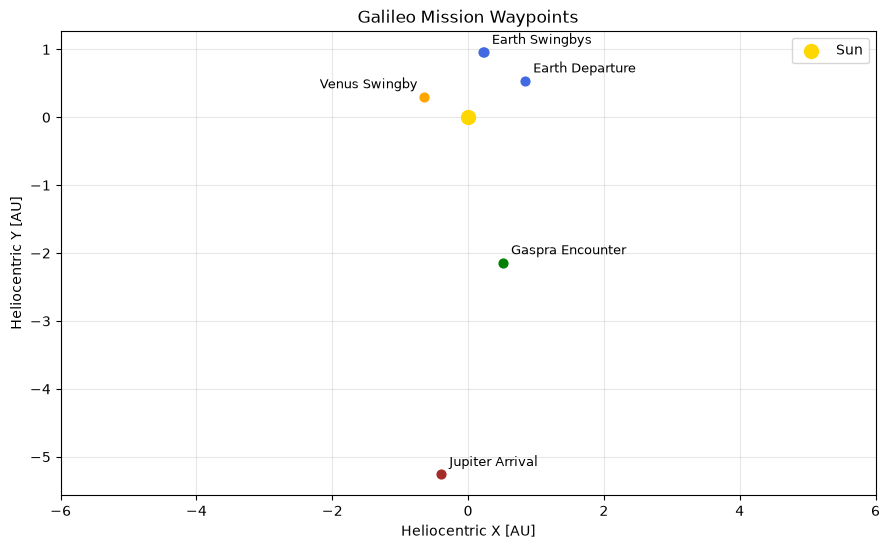

In [42]:
colors = {
    2: "orange",      # Venus
    3: "royalblue",   # Earth
    5: "brown",       # Jupiter
    None: "green"     # Gaspra
}

fig, ax = plt.subplots(figsize=(9, 9))

# Plot Sun
ax.scatter(0, 0, color="gold", marker="o", s=100, label="Sun", zorder=5)

# Plot waypoints
for flyby in flybys:
    
    r = flyby.hci_r / AU_TO_KM
    ax.scatter(r[0], r[1], color=colors[flyby.planet_num], s=40, zorder=3)
    
    # Dumb dub dumb
    name = flyby.name
    if "Venus" in name:
        ax.annotate(name, (r[0], r[1]),xytext=(-75, 6),textcoords="offset points",fontsize=9)
    elif "Earth Swingby" not in name:
        ax.annotate(name, (r[0], r[1]),xytext=(6, 6),textcoords="offset points",fontsize=9)
    elif "#1" in name:
        ax.annotate("Earth Swingbys", (r[0], r[1]),xytext=(6, 6),textcoords="offset points",fontsize=9)

ax.set_xlabel("Heliocentric X [AU]")
ax.set_ylabel("Heliocentric Y [AU]")
ax.set_title("Galileo Mission Waypoints")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.set_xlim(-6, 6)
ax.legend()

plt.tight_layout()
plt.show()

## Problem 2

### Part a

In [ ]:
# heliocentric asymptotic arrival and departure velocity vectors, using Lambert
# • planetocentric asymptotic arrival and departure velocity vectors
# (although these velocity vectors are measured relative to the swingby planet’s
# reference frame, they can be left expressed in heliocentric coordinates)
# • planetocentric asymptotic arrival and departure speeds 𝑣 ⃑ 𝑎𝑛𝑑 𝑣 ⃑
# • hyperbolic passage turning angle δ planet
# • hyperbolic passage eccentricity e planet

def asymptotic_velocities(r1: np.ndarray, r2: np.ndarray):
    """heliocentric asymptotic arrival and departure velocity vectors, using Lambert
    
    `AA279lambert_curtis.m` signature:
    function [v1_out, v2_out, error_out] = AA279lambert_curtis(mu, r1_in, r2_in, dm, nrev, dtsec)
    """
    
    dv1, dv2 =  eng.AA279lambert_curtis(MU_SUN, r1, r2, "pro", 1, nargout=2)
    
    


# Extra (junk)

In [ ]:
test = False
if test:
    # Just visualizing
    from dynamics import two_body


    def sun_two_body(t,x):
        del t
        return two_body(x, MU_SUN)

    
    jd = 2461333.837872444
    labels = [
        "Mercury",
        "Venus",
        "Earth",
        "Mars",
    ]

    planet_rv = []
    for planet_num in range(4):
        test_r, test_v = hci_rv(planet_num+1,jd) # 2026-10-20 08:06:32.179
        test_t = np.arange(0, 10*DAY_TO_SEC, HOUR_TO_SEC)
        planet_rv.append(
            solve_ivp(sun_two_body, (test_t[0], test_t[-1]), np.concatenate((test_r, test_v)), method='LSODA', t_eval=test_t, rtol=1e-6, atol=1e-9).y
        )
        
    planet_r = [r.T[:,:3] for r in planet_rv]
    plot_3d(planet_r, test_t, bodies={"name": "Sun", "radius": R_SUN}, labels=labels, title="Test of Mercury-Earth")